<a href="https://colab.research.google.com/github/vijay-negi07/India-States_and_Union-Territory_Quiz_Game/blob/main/customer-analytics-dashbaord.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import urllib.request
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

online_retail = fetch_ucirepo(id=352)

df = online_retail.data.original

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (541909, 8)


In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [ ]:
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})
print(missing_summary)

             Missing Values  Missing Percentage
InvoiceNo                 0            0.000000
StockCode                 0            0.000000
Description            1454            0.268311
Quantity                  0            0.000000
InvoiceDate               0            0.000000
UnitPrice                 0            0.000000
CustomerID           135080           24.926694
Country                   0            0.000000


In [ ]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 5268


In [ ]:
description_counts = (
    df.dropna(subset=["Description"])
      .groupby("StockCode")["Description"]
      .nunique()
)

print("StockCodes with multiple descriptions:",
      (description_counts > 1).sum())

StockCodes with multiple descriptions: 650


In [ ]:
multiple_descriptions = (
    df.dropna(subset=["Description"])
      .groupby("StockCode")["Description"]
      .nunique()
)

multiple_descriptions = multiple_descriptions[
    multiple_descriptions > 1
]

print("Total StockCodes with multiple descriptions:",
      len(multiple_descriptions))

print(multiple_descriptions.head(10))


Total StockCodes with multiple descriptions: 650
StockCode
10080     2
10133     2
15058A    2
15058C    2
16008     2
16045     2
16156L    2
16162M    2
16168M    2
16169E    2
Name: Description, dtype: int64


In [ ]:
sample_codes = multiple_descriptions.head(5).index

df[df["StockCode"].isin(sample_codes)][
    ["StockCode", "Description"]
].drop_duplicates().sort_values("StockCode")

,StockCode,Description
103332,10080,GROOVY CACTUS INFLATABLE
279310,10080,NaN
454350,10080,check
741,10133,COLOURING PENCILS BROWN TUBE
474647,10133,damaged
23437,15058A,BLUE POLKADOT GARDEN PARASOL
108588,15058A,NaN
192289,15058A,wet/rusty
81425,15058C,ICE CREAM DESIGN GARDEN PARASOL
192290,15058C,wet/rusty


In [ ]:
# Original dataset ka backup
df_raw = df.copy()

# Product descriptions ki mapping banao
description_map = (
    df[
        df["Description"].notna()
        & ~df["Description"].str.lower().isin(
            ["check", "damaged", "wet/rusty"]
        )
    ]
    .drop_duplicates(subset=["StockCode"])
    .set_index("StockCode")["Description"]
)

# Sirf missing descriptions fill karo
df["Description"] = df["Description"].fillna(
    df["StockCode"].map(description_map)
)

print(
    "Missing descriptions after filling:",
    df["Description"].isna().sum()
)


Missing descriptions after filling: 112


In [ ]:
missing_description = df[df["Description"].isna()]

print("Remaining missing descriptions:", len(missing_description))

missing_description[["StockCode", "Description", "CustomerID"]].head(20)



Remaining missing descriptions: 112


,StockCode,Description,CustomerID
1970,21134,NaN,NaN
1987,85226A,NaN,NaN
1988,85044,NaN,NaN
2024,20950,NaN,NaN
2026,84670,NaN,NaN
7187,35951,NaN,NaN
7193,21653,NaN,NaN
19628,20849,NaN,NaN
19631,72803B,NaN,NaN
21782,85018C,NaN,NaN


In [ ]:
missing_codes = df.loc[
    df["Description"].isna(), "StockCode"
].unique()

available_codes = df.loc[
    df["Description"].notna()
    & ~df["Description"].str.lower().isin(
        ["check", "damaged", "wet/rusty"]
    ),
    "StockCode"
].unique()

unrecoverable_codes = set(missing_codes) - set(available_codes)

print("Missing description rows:", df["Description"].isna().sum())
print("Unique missing StockCodes:", len(missing_codes))
print("StockCodes without a valid description:", len(unrecoverable_codes))


Missing description rows: 112
Unique missing StockCodes: 112
StockCodes without a valid description: 112


In [ ]:
#Missing CustomerID
print("Missing CustomerID:", df["CustomerID"].isna().sum())

print(
    "Percentage missing:",
    round(df["CustomerID"].isna().mean() * 100, 2),
    "%"
)

Missing CustomerID: 135080
Percentage missing: 24.93 %


In [ ]:
# Display first 10 duplicate rows
duplicates = df[df.duplicated(keep=False)]

print("Total rows involved in duplicates:", len(duplicates))
display(duplicates.head(10))

Total rows involved in duplicates: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom


In [ ]:
# Count rows before removing duplicates
rows_before = len(df)

# Remove exact duplicate rows
df = df.drop_duplicates()

# Count rows after removing duplicates
rows_after = len(df)

print("Rows before removing duplicates:", rows_before)
print("Rows after removing duplicates:", rows_after)
print("Duplicate rows removed:", rows_before - rows_after)
print("Dataset shape after cleaning:", df.shape)

Rows before removing duplicates: 541909
Rows after removing duplicates: 536641
Duplicate rows removed: 5268
Dataset shape after cleaning: (536641, 8)


In [ ]:
# Count cancellation invoices
cancellations = df["InvoiceNo"].astype(str).str.startswith("C")

print("Cancellation transaction rows:", cancellations.sum())

# Count negative quantity rows
negative_quantity = df["Quantity"] < 0

print("Rows with negative Quantity:", negative_quantity.sum())

# Display sample cancellation transactions
display(df[cancellations].head(10))

Cancellation transaction rows: 9251
Rows with negative Quantity: 10587


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/2010 12:38,4.25,17897.0,United Kingdom


In [ ]:
# Identify cancellation invoices
cancellations = df["InvoiceNo"].astype(str).str.startswith("C")

# Identify negative quantities
negative_quantity = df["Quantity"] < 0

# Negative quantities in cancellation invoices
print(
    "Negative quantities in cancellation invoices:",
    (cancellations & negative_quantity).sum()
)

# Negative quantities in non-cancellation invoices
print(
    "Negative quantities in non-cancellation invoices:",
    (~cancellations & negative_quantity).sum()
)

# Cancellation invoices with non-negative quantities
print(
    "Cancellation invoices with non-negative quantities:",
    (cancellations & ~negative_quantity).sum()
)

Negative quantities in cancellation invoices: 9251
Negative quantities in non-cancellation invoices: 1336
Cancellation invoices with non-negative quantities: 0


In [ ]:
# Check zero and negative quantities
print("Zero Quantity rows:", (df["Quantity"] == 0).sum())
print("Negative Quantity rows:", (df["Quantity"] < 0).sum())

# Check zero and negative unit prices
print("Zero UnitPrice rows:", (df["UnitPrice"] == 0).sum())
print("Negative UnitPrice rows:", (df["UnitPrice"] < 0).sum())

# Display rows with negative unit prices
display(df[df["UnitPrice"] < 0].head(10))

Zero Quantity rows: 0
Negative Quantity rows: 10587
Zero UnitPrice rows: 2510
Negative UnitPrice rows: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,8/12/2011 14:51,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,8/12/2011 14:52,-11062.06,NaN,United Kingdom


In [ ]:
# Display negative UnitPrice transactions
print("Negative UnitPrice transactions:")
display(df[df["UnitPrice"] < 0])

# Display first 10 zero UnitPrice transactions
print("Sample zero UnitPrice transactions:")
display(df[df["UnitPrice"] == 0].head(10))

# Check descriptions of zero-price transactions
print("Most common descriptions with zero UnitPrice:")
display(
    df.loc[df["UnitPrice"] == 0, "Description"]
      .value_counts(dropna=False)
      .head(15)
)

Negative UnitPrice transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,8/12/2011 14:51,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,8/12/2011 14:52,-11062.06,NaN,United Kingdom


Sample zero UnitPrice transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,RETROSPOT TEA SET CERAMIC 11 PC,56,12/1/2010 11:52,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,12/1/2010 14:32,0.0,NaN,United Kingdom
1971,536546,22145,CHRISTMAS CRAFT HEART STOCKING,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1972,536547,37509,NEW ENGLAND MUG W GIFT BOX,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom
2025,536553,37461,FUNKY MONKEY MUG,3,12/1/2010 14:35,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,12/1/2010 14:35,0.0,NaN,United Kingdom
2406,536589,21777,RECIPE BOX WITH METAL HEART,-10,12/1/2010 16:50,0.0,NaN,United Kingdom


Most common descriptions with zero UnitPrice:


,count
Description,
check,159
NaN,112
?,49
damages,45
damaged,43
found,25
sold as set on dotcom,20
adjustment,16
Damaged,14


In [ ]:
# Convert InvoiceDate to datetime format
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

# Check the data type
print("InvoiceDate data type:", df["InvoiceDate"].dtype)

# Check invalid dates
print("Invalid InvoiceDate rows:", df["InvoiceDate"].isna().sum())

# Display sample dates
display(df[["InvoiceNo", "InvoiceDate"]].head())

InvoiceDate data type: datetime64[ns]
Invalid InvoiceDate rows: 0


/tmp/ipykernel_1551/532146332.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["InvoiceDate"] = pd.to_datetime(


,InvoiceNo,InvoiceDate
0,536365,2010-12-01 08:26:00
1,536365,2010-12-01 08:26:00
2,536365,2010-12-01 08:26:00
3,536365,2010-12-01 08:26:00
4,536365,2010-12-01 08:26:00


In [ ]:
# Create an independent copy of the DataFrame
df = df.copy()

# Convert InvoiceDate safely
df.loc[:, "InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print("InvoiceDate data type:", df["InvoiceDate"].dtype)
print("Invalid dates:", df["InvoiceDate"].isna().sum())


InvoiceDate data type: datetime64[ns]
Invalid dates: 0


In [ ]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows remaining:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Final dataset shape: (536641, 8)

Missing values:
InvoiceNo           0
StockCode           0
Description       112
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

Duplicate rows remaining: 0

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [ ]:
# Calculate revenue for each transaction
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Display sample transactions
display(
    df[
        [
            "InvoiceNo",
            "Quantity",
            "UnitPrice",
            "Revenue"
        ]
    ].head(10)
)

# Check revenue statistics
print("\nRevenue statistics:")
print(df["Revenue"].describe())

,InvoiceNo,Quantity,UnitPrice,Revenue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34
5,536365,2,7.65,15.30
6,536365,6,4.25,25.50
7,536366,6,1.85,11.10
8,536366,6,1.85,11.10
9,536367,32,1.69,54.08



Revenue statistics:
count    536641.000000
mean         18.123861
std         380.656263
min     -168469.600000
25%           3.750000
50%           9.870000
75%          17.400000
max      168469.600000
Name: Revenue, dtype: float64


In [ ]:
# Identify cancellation invoices
cancellation_mask = df["InvoiceNo"].astype(str).str.startswith("C")

# Identify negative UnitPrice transactions
negative_price_mask = df["UnitPrice"] < 0

# Display unusual transactions
print("Negative UnitPrice transactions:")
display(df.loc[negative_price_mask])

print("\nCancellation transactions:", cancellation_mask.sum())
print("Negative UnitPrice transactions:", negative_price_mask.sum())

# Calculate revenue excluding negative-price adjustments
normal_price_df = df.loc[~negative_price_mask].copy()

print("\nRows before exclusion:", len(df))
print("Rows after excluding negative-price adjustments:", len(normal_price_df))

Negative UnitPrice transactions:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,-11062.06
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,-11062.06



Cancellation transactions: 9251
Negative UnitPrice transactions: 2

Rows before exclusion: 536641
Rows after excluding negative-price adjustments: 536639


In [ ]:
#Exploratory Data Analysis(EDA)

In [ ]:
# Create a separate dataset for EDA
eda_df = normal_price_df.copy()

# Check dataset dimensions
print("Dataset shape:", eda_df.shape)

# Display the first 5 rows
display(eda_df.head())

# Check available columns
print("\nColumns:")
print(eda_df.columns.tolist())

Dataset shape: (536639, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34



Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']


In [ ]:
#Calculate Monthly Revenue
# Extract year and month from InvoiceDate
eda_df["YearMonth"] = eda_df["InvoiceDate"].dt.to_period("M")

# Calculate total revenue for each month
monthly_revenue = (
    eda_df.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

# Display monthly revenue
display(monthly_revenue)



,YearMonth,Revenue
0,2010-12,746723.610
1,2011-01,558448.560
2,2011-02,497026.410
3,2011-03,682013.980
4,2011-04,492367.841
5,2011-05,722094.100
6,2011-06,689977.230
7,2011-07,680156.991
8,2011-08,703510.580
9,2011-09,1017596.682


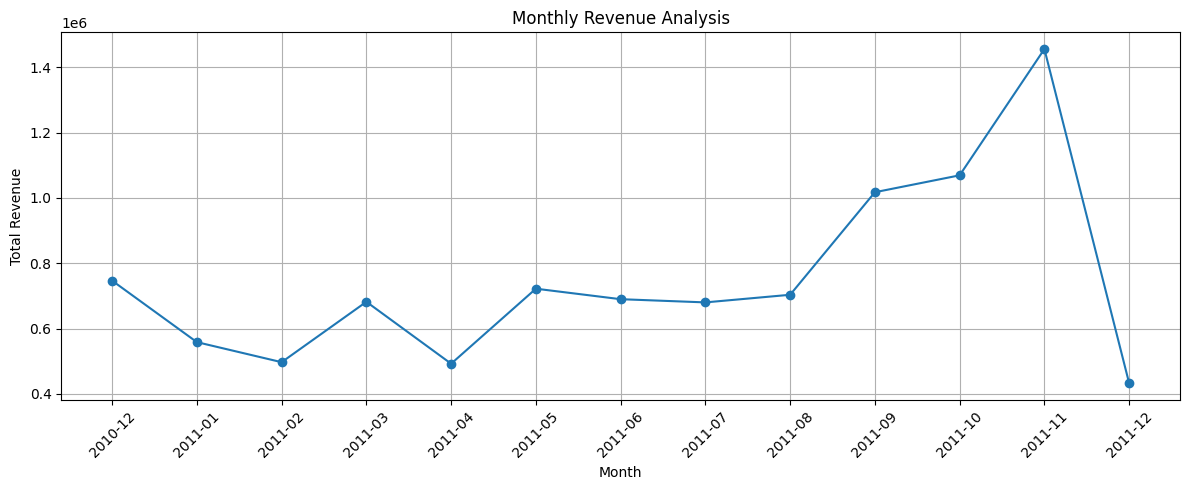

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["YearMonth"].astype(str),
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#Finding the Top 10 Best-Selling Products


In [ ]:
# Remove rows with missing product descriptions for this analysis
product_df = eda_df.dropna(subset=["Description"]).copy()

# Calculate total quantity sold for each product
top_products = (
    product_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Display the top 10 products
display(top_products)



,Description,Quantity
0,WORLD WAR 2 GLIDERS ASSTD DESIGNS,53751
1,JUMBO BAG RED RETROSPOT,47260
2,POPCORN HOLDER,36322
3,ASSORTED COLOUR BIRD ORNAMENT,36282
4,PACK OF 72 RETROSPOT CAKE CASES,36016
5,WHITE HANGING HEART T-LIGHT HOLDER,35298
6,RABBIT NIGHT LIGHT,30963
7,MINI PAINT SET VINTAGE,26437
8,PACK OF 12 LONDON TISSUES,26299
9,PACK OF 60 PINK PAISLEY CAKE CASES,24719


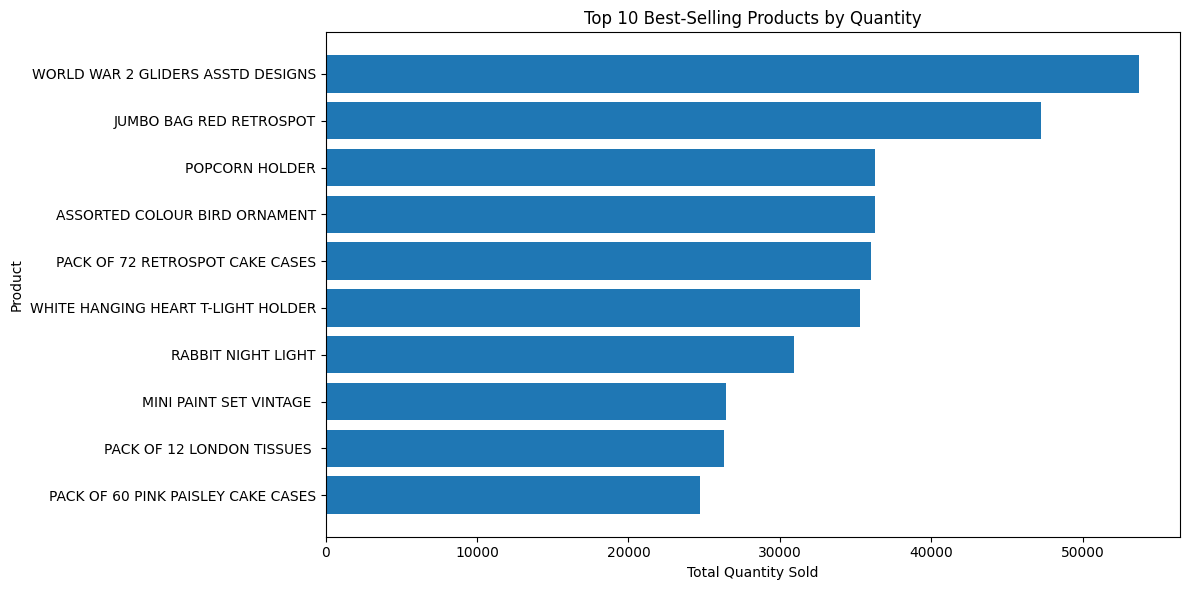

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    top_products["Description"],
    top_products["Quantity"]
)

plt.title("Top 10 Best-Selling Products by Quantity")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
#Country Wise Revenue


In [ ]:
# Calculate total revenue generated by each country
country_revenue = (
    eda_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Display top 10 countries
top_countries = country_revenue.head(10)

display(top_countries)

,Country,Revenue
0,United Kingdom,8189252.304
1,Netherlands,284661.540
2,EIRE,262993.380
3,Germany,221509.470
4,France,197317.110
5,Australia,137009.770
6,Switzerland,56363.050
7,Spain,54756.030
8,Belgium,40910.960
9,Sweden,36585.410


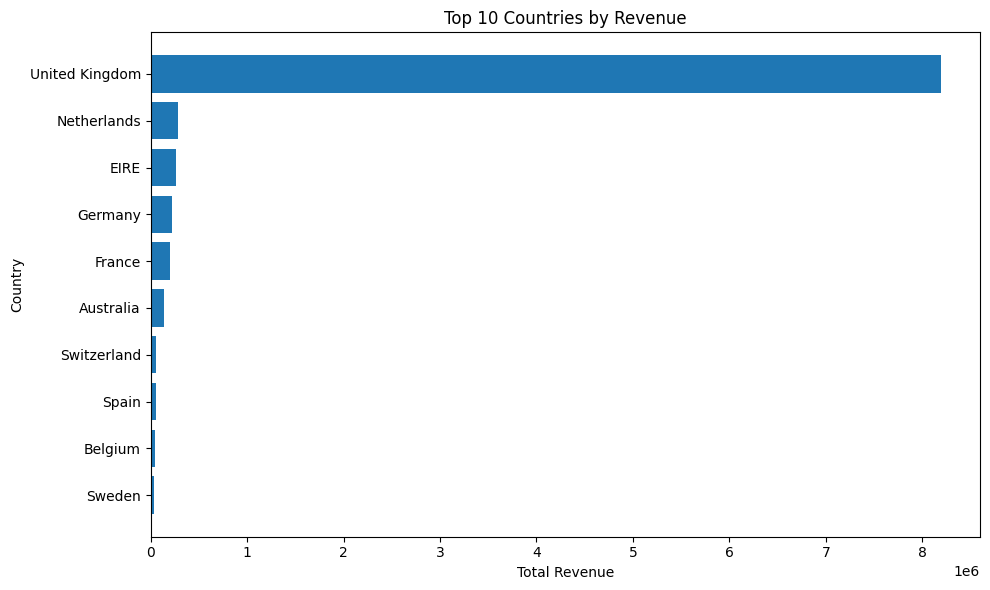

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries["Country"],
    top_countries["Revenue"]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
!pip install seaborn

In [ ]:
#Purchase Frequency Analysis

In [ ]:
# Remove rows with missing CustomerID
customer_df = eda_df.dropna(subset=["CustomerID"]).copy()

# Count unique invoices for each customer
purchase_frequency = (
    customer_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index(name="Purchase_Frequency")
)

# Display the first 10 customers
display(purchase_frequency.head(10))

# Summary statistics
print("Total customers:", purchase_frequency["CustomerID"].nunique())
print(
    "Average purchase frequency:",
    round(purchase_frequency["Purchase_Frequency"].mean(), 2)
)

,CustomerID,Purchase_Frequency
0,12346.0,2
1,12347.0,7
2,12348.0,4
3,12349.0,1
4,12350.0,1
5,12352.0,11
6,12353.0,1
7,12354.0,1
8,12355.0,1
9,12356.0,3


Total customers: 4372
Average purchase frequency: 5.08


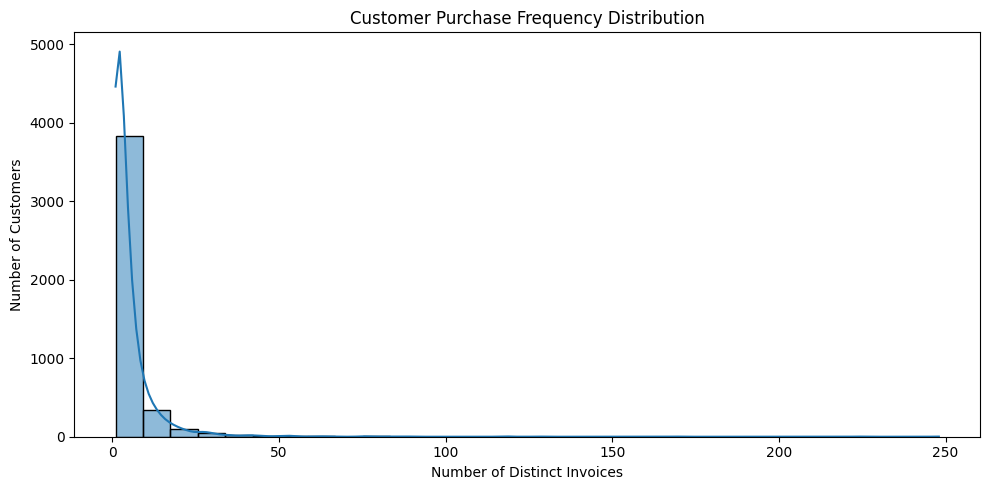

In [ ]:
import seaborn as sns
plt.figure(figsize=(10, 5))

sns.histplot(
    data=purchase_frequency,
    x="Purchase_Frequency",
    bins=30,
    kde=True
)

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [ ]:
#Customer Segmentation


In [ ]:
# Create a copy of the cleaned dataset
customer_data = eda_df.dropna(subset=["CustomerID"]).copy()

# Calculate customer-level metrics
customer_summary = (
    customer_data.groupby("CustomerID")
    .agg(
        Last_Purchase=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

# Display the first 10 customers
display(customer_summary.head(10))

# Check the dataset shape
print("Customer dataset shape:", customer_summary.shape)
print("Total unique customers:", customer_summary["CustomerID"].nunique())

,CustomerID,Last_Purchase,Frequency,Monetary
0,12346.0,2011-01-18 10:17:00,2,0.00
1,12347.0,2011-12-07 15:52:00,7,4310.00
2,12348.0,2011-09-25 13:13:00,4,1797.24
3,12349.0,2011-11-21 09:51:00,1,1757.55
4,12350.0,2011-02-02 16:01:00,1,334.40
5,12352.0,2011-11-03 14:37:00,11,1545.41
6,12353.0,2011-05-19 17:47:00,1,89.00
7,12354.0,2011-04-21 13:11:00,1,1079.40
8,12355.0,2011-05-09 13:49:00,1,459.40
9,12356.0,2011-11-17 08:40:00,3,2811.43


Customer dataset shape: (4372, 4)
Total unique customers: 4372


In [ ]:
#Calculating recency
# Set the reference date as one day after the last invoice date
snapshot_date = customer_data["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate Recency for each customer
customer_summary["Recency"] = (
    snapshot_date - customer_summary["Last_Purchase"]
).dt.days

# Display customer RFM metrics
display(
    customer_summary[
        ["CustomerID", "Last_Purchase", "Recency", "Frequency", "Monetary"]
    ].head(10)
)

print("Reference date:", snapshot_date)

,CustomerID,Last_Purchase,Recency,Frequency,Monetary
0,12346.0,2011-01-18 10:17:00,326,2,0.00
1,12347.0,2011-12-07 15:52:00,2,7,4310.00
2,12348.0,2011-09-25 13:13:00,75,4,1797.24
3,12349.0,2011-11-21 09:51:00,19,1,1757.55
4,12350.0,2011-02-02 16:01:00,310,1,334.40
5,12352.0,2011-11-03 14:37:00,36,11,1545.41
6,12353.0,2011-05-19 17:47:00,204,1,89.00
7,12354.0,2011-04-21 13:11:00,232,1,1079.40
8,12355.0,2011-05-09 13:49:00,214,1,459.40
9,12356.0,2011-11-17 08:40:00,23,3,2811.43


Reference date: 2011-12-10 12:50:00


In [ ]:
#Check RFM Data
# Select the RFM columns
rfm = customer_summary[
    ["CustomerID", "Recency", "Frequency", "Monetary"]
].copy()

# Check the dataset
print("RFM Dataset Shape:", rfm.shape)

print("\nMissing Values:")
print(rfm.isnull().sum())

print("\nDuplicate Customer IDs:")
print(rfm["CustomerID"].duplicated().sum())

print("\nRFM Statistical Summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

RFM Dataset Shape: (4372, 4)

Missing Values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Duplicate Customer IDs:
0

RFM Statistical Summary:


,Recency,Frequency,Monetary
count,4372.000000,4372.000000,4372.000000
mean,92.047118,5.075480,1893.531433
std,100.765435,9.338754,8218.696204
min,1.000000,1.000000,-4287.630000
25%,17.000000,1.000000,291.795000
50%,50.000000,3.000000,644.070000
75%,143.000000,5.000000,1608.335000
max,374.000000,248.000000,279489.020000


In [ ]:
#Check Negative Monetary Values
print("Customers with negative Monetary values:",
      (rfm["Monetary"] < 0).sum())

print("Customers with zero Monetary values:",
      (rfm["Monetary"] == 0).sum())

print("Customers with positive Monetary values:",
      (rfm["Monetary"] > 0).sum())

Customers with negative Monetary values: 42
Customers with zero Monetary values: 8
Customers with positive Monetary values: 4322


In [ ]:
# Preparing Data for K-means clustering
# Keep customers with positive net revenue
rfm_model = rfm[rfm["Monetary"] > 0].copy()

# Select features for clustering
rfm_features = rfm_model[
    ["Recency", "Frequency", "Monetary"]
].copy()

print("Original customers:", len(rfm))
print("Customers selected for clustering:", len(rfm_model))

display(rfm_features.head())

Original customers: 4372
Customers selected for clustering: 4322


,Recency,Frequency,Monetary
1,2,7,4310.00
2,75,4,1797.24
3,19,1,1757.55
4,310,1,334.40
5,36,11,1545.41


In [ ]:
# Apply log transformation to reduce skewness
rfm_log = rfm_features.copy()

rfm_log["Recency"] = np.log1p(rfm_log["Recency"])
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

display(rfm_log.head())

,Recency,Frequency,Monetary
1,1.098612,2.079442,8.368925
2,4.330733,1.609438,7.494564
3,2.995732,0.693147,7.472245
4,5.739793,0.693147,5.815324
5,3.610918,2.484907,7.343691


In [ ]:
#Applying StandardScaler
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Scale the transformed RFM features
rfm_scaled = scaler.fit_transform(rfm_log)

print("Scaled dataset shape:", rfm_scaled.shape)
print("\nFirst 5 scaled rows:")
print(rfm_scaled[:5])


print("Feature means after scaling:")
print(rfm_scaled.mean(axis=0).round(3))

print("\nFeature standard deviations after scaling:")
print(rfm_scaled.std(axis=0).round(3))

Scaled dataset shape: (4322, 3)

First 5 scaled rows:
[[-1.96922793  0.85451058  1.43140291]
 [ 0.40161678  0.21730915  0.73951409]
 [-0.57764116 -1.02494031  0.72185305]
 [ 1.43519856 -1.02494031 -0.58928103]
 [-0.12638653  1.40421472  0.6201277 ]]
Feature means after scaling:
[ 0.  0. -0.]

Feature standard deviations after scaling:
[1. 1. 1.]


In [ ]:
#Finding the optimal number of clusters.
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Calculate WCSS for different numbers of clusters
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

print("WCSS values:", wcss)

WCSS values: [12966.000000000002, 6473.864546178448, 4897.932390678426, 3962.156470858877, 3346.725357534089, 2903.7246132101686, 2604.5785121060494, 2396.450050894685, 2228.570475180009, 2055.229538861168]


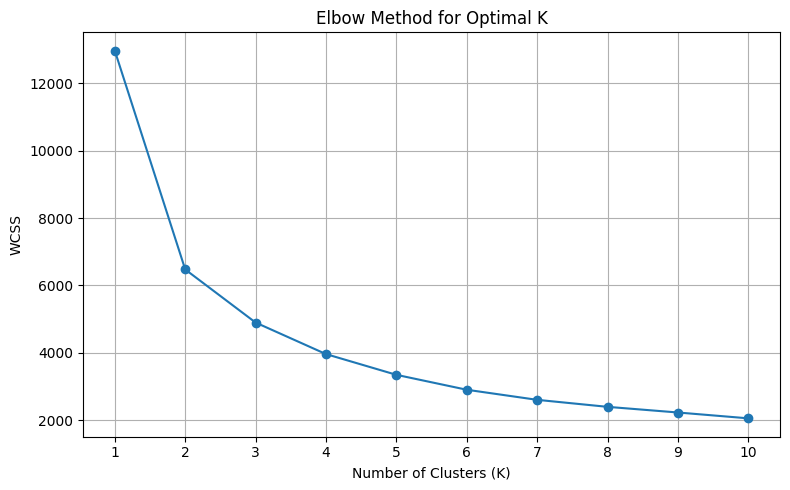

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#Apply K-Means Clustering

In [ ]:
#Train the K-Means Model
from sklearn.cluster import KMeans

# Create the K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model and assign cluster labels
rfm_model["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Display customer data with cluster labels
display(rfm_model.head(10))

print("\nCluster distribution:")
print(rfm_model["Cluster"].value_counts().sort_index())

,CustomerID,Recency,Frequency,Monetary,Cluster
1,12347.0,2,7,4310.00,2
2,12348.0,75,4,1797.24,1
3,12349.0,19,1,1757.55,1
4,12350.0,310,1,334.40,0
5,12352.0,36,11,1545.41,1
6,12353.0,204,1,89.00,0
7,12354.0,232,1,1079.40,0
8,12355.0,214,1,459.40,0
9,12356.0,23,3,2811.43,1
10,12357.0,33,1,6207.67,1



Cluster distribution:
Cluster
0    1900
1    1684
2     738
Name: count, dtype: int64


In [ ]:
#Calculate Clustering Profiles
# Calculate the average RFM values for each cluster
cluster_summary = (
    rfm_model.groupby("Cluster")
    .agg(
        Number_of_Customers=("CustomerID", "count"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean")
    )
    .round(2)
    .reset_index()
)

display(cluster_summary)

,Cluster,Number_of_Customers,Average_Recency,Average_Frequency,Average_Monetary
0,0,1900,160.76,1.51,348.25
1,1,1684,44.13,4.12,1243.24
2,2,738,14.49,16.66,7501.97


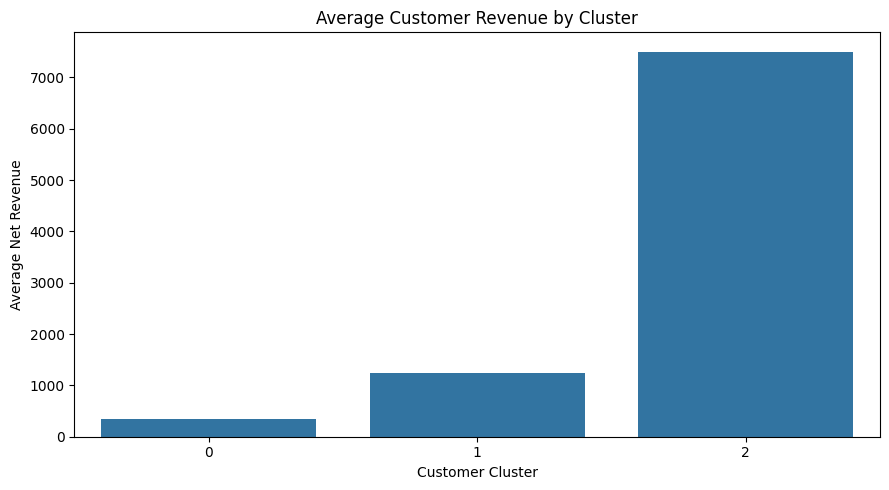

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cluster_summary,
    x="Cluster",
    y="Average_Monetary"
)

plt.title("Average Customer Revenue by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Net Revenue")

plt.tight_layout()
plt.show()

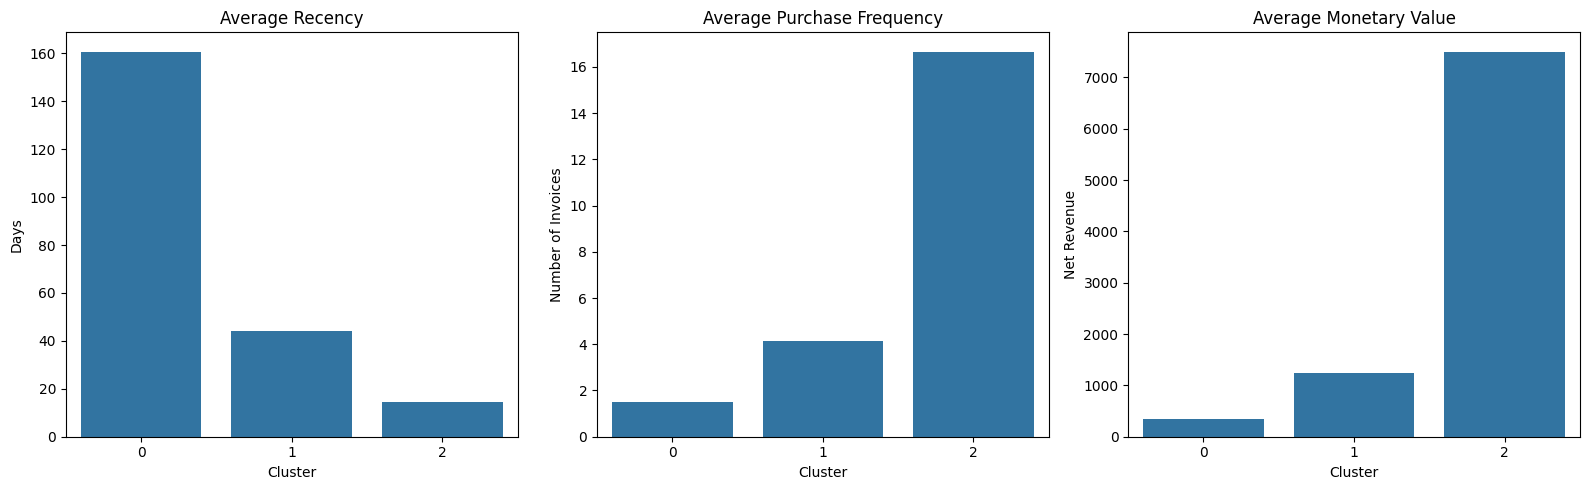

In [ ]:
#Visualize All three Customer Segments
# Convert cluster summary into a format suitable for plotting
cluster_comparison = cluster_summary.melt(
    id_vars="Cluster",
    value_vars=[
        "Average_Recency",
        "Average_Frequency",
        "Average_Monetary"
    ],
    var_name="Metric",
    value_name="Average_Value"
)

# Create separate charts for each metric
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(
    data=cluster_comparison[
        cluster_comparison["Metric"] == "Average_Recency"
    ],
    x="Cluster",
    y="Average_Value",
    ax=axes[0]
)
axes[0].set_title("Average Recency")
axes[0].set_ylabel("Days")

sns.barplot(
    data=cluster_comparison[
        cluster_comparison["Metric"] == "Average_Frequency"
    ],
    x="Cluster",
    y="Average_Value",
    ax=axes[1]
)
axes[1].set_title("Average Purchase Frequency")
axes[1].set_ylabel("Number of Invoices")

sns.barplot(
    data=cluster_comparison[
        cluster_comparison["Metric"] == "Average_Monetary"
    ],
    x="Cluster",
    y="Average_Value",
    ax=axes[2]
)
axes[2].set_title("Average Monetary Value")
axes[2].set_ylabel("Net Revenue")

plt.tight_layout()
plt.show()

In [ ]:
#Model : Predictive Machine Leaning

In [ ]:
# Check the date range of the dataset

print("Dataset Start Date:", df["InvoiceDate"].min())
print("Dataset End Date:", df["InvoiceDate"].max())

print("Total Rows:", len(df))
print("Total Unique Customers:", df["CustomerID"].nunique())


Dataset Start Date: 2010-12-01 08:26:00
Dataset End Date: 2011-12-09 12:50:00
Total Rows: 536641
Total Unique Customers: 4372


In [ ]:
# Check the actual datetime format and date range

print("Data type:", df["InvoiceDate"].dtype)

print("\nFirst 5 dates:")
print(df["InvoiceDate"].head().to_string(index=False))

print("\nEarliest date:", df["InvoiceDate"].min())
print("Latest date:", df["InvoiceDate"].max())

Data type: datetime64[ns]

First 5 dates:
2010-12-01 08:26:00
2010-12-01 08:26:00
2010-12-01 08:26:00
2010-12-01 08:26:00
2010-12-01 08:26:00

Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00


In [ ]:
# Convert InvoiceDate from string to datetime

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

# Verify the conversion

print("Data type:", df["InvoiceDate"].dtype)
print("Earliest date:", df["InvoiceDate"].min())
print("Latest date:", df["InvoiceDate"].max())
print("Missing dates:", df["InvoiceDate"].isna().sum())


Data type: datetime64[ns]
Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00
Missing dates: 0


In [ ]:
# Define chronological cutoff of dates
feature_cutoff = pd.Timestamp("2011-10-01 00:00:00")
prediction_end = feature_cutoff + pd.Timedelta(days=30)

print("Feature Cutoff:", feature_cutoff)
print("Prediction Window Start:", feature_cutoff)
print("Prediction Window End:", prediction_end)

Feature Cutoff: 2011-10-01 00:00:00
Prediction Window Start: 2011-10-01 00:00:00
Prediction Window End: 2011-10-31 00:00:00


In [ ]:
#Prepareing Valid Purchase Date
# Keep only valid purchase transactions

purchase_df = df[
    df["CustomerID"].notna()
    & (~df["InvoiceNo"].astype(str).str.startswith("C"))
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
].copy()

# Calculate transaction revenue
purchase_df["Revenue"] = (
    purchase_df["Quantity"] * purchase_df["UnitPrice"]
)

print("Valid purchase transactions:", len(purchase_df))
print("Unique customers:", purchase_df["CustomerID"].nunique())
print("Date range:")
print(purchase_df["InvoiceDate"].min())
print(purchase_df["InvoiceDate"].max())

Valid purchase transactions: 392692
Unique customers: 4338
Date range:
2010-12-01 08:26:00
2011-12-09 12:50:00


In [ ]:
# Use only historical purchases before the cutoff date

historical_df = purchase_df[
    purchase_df["InvoiceDate"] < feature_cutoff
].copy()

# Calculate customer-level features
customer_features = (
    historical_df.groupby("CustomerID")
    .agg(
        Last_Purchase=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

# Calculate recency in days
customer_features["Recency"] = (
    feature_cutoff - customer_features["Last_Purchase"]
).dt.days

# Display the features
display(customer_features.head(10))

print("Customers with historical purchases:", len(customer_features))
print("Features:", customer_features.columns.tolist())

,CustomerID,Last_Purchase,Frequency,Monetary,Recency
0,12346.0,2011-01-18 10:01:00,1,77183.60,255
1,12347.0,2011-08-02 08:48:00,5,2790.86,59
2,12348.0,2011-09-25 13:13:00,4,1797.24,5
3,12350.0,2011-02-02 16:01:00,1,334.40,240
4,12352.0,2011-09-28 14:58:00,7,2194.31,2
5,12353.0,2011-05-19 17:47:00,1,89.00,134
6,12354.0,2011-04-21 13:11:00,1,1079.40,162
7,12355.0,2011-05-09 13:49:00,1,459.40,144
8,12356.0,2011-04-08 12:33:00,2,2753.08,175
9,12358.0,2011-07-12 10:04:00,1,484.86,80


Customers with historical purchases: 3616
Features: ['CustomerID', 'Last_Purchase', 'Frequency', 'Monetary', 'Recency']


In [ ]:
# Get purchases made during the next 30 days

future_df = purchase_df[
    (purchase_df["InvoiceDate"] >= feature_cutoff)
    & (purchase_df["InvoiceDate"] < prediction_end)
].copy()

# Identify customers who purchased during the prediction window
repeat_customers = future_df["CustomerID"].unique()

# Create target variable
customer_features["Repeat_Purchase"] = (
    customer_features["CustomerID"]
    .isin(repeat_customers)
    .astype(int)
)

# Display the target distribution
print("Target variable distribution:")
print(customer_features["Repeat_Purchase"].value_counts())

print("\nTarget percentages:")
print(
    (customer_features["Repeat_Purchase"].value_counts(normalize=True) * 100)
    .round(2)
)

display(customer_features.head(10))

Target variable distribution:
Repeat_Purchase
0    2639
1     977
Name: count, dtype: int64

Target percentages:
Repeat_Purchase
0    72.98
1    27.02
Name: proportion, dtype: float64


,CustomerID,Last_Purchase,Frequency,Monetary,Recency,Repeat_Purchase
0,12346.0,2011-01-18 10:01:00,1,77183.60,255,0
1,12347.0,2011-08-02 08:48:00,5,2790.86,59,0
2,12348.0,2011-09-25 13:13:00,4,1797.24,5,0
3,12350.0,2011-02-02 16:01:00,1,334.40,240,0
4,12352.0,2011-09-28 14:58:00,7,2194.31,2,0
5,12353.0,2011-05-19 17:47:00,1,89.00,134,0
6,12354.0,2011-04-21 13:11:00,1,1079.40,162,0
7,12355.0,2011-05-09 13:49:00,1,459.40,144,0
8,12356.0,2011-04-08 12:33:00,2,2753.08,175,0
9,12358.0,2011-07-12 10:04:00,1,484.86,80,0


In [ ]:
# Select input features
X = customer_features[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Select target variable
y = customer_features["Repeat_Purchase"].copy()

# Check the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
display(X.head())

print("\nTarget values:")
display(y.head())

Features shape: (3616, 3)
Target shape: (3616,)

Input features:


,Recency,Frequency,Monetary
0,255,1,77183.60
1,59,5,2790.86
2,5,4,1797.24
3,240,1,334.40
4,2,7,2194.31



Target values:


,Repeat_Purchase
0,0
1,0
2,0
3,0
4,0


In [ ]:
# Define historical training cutoffs and testing cutoff

training_cutoffs = [
    pd.Timestamp("2011-06-01"),
    pd.Timestamp("2011-07-01"),
    pd.Timestamp("2011-08-01")
]

test_cutoff = pd.Timestamp("2011-09-01")

print("Training cutoffs:")
for date in training_cutoffs:
    print(date.date())

print("\nTesting cutoff:", test_cutoff.date())
print("Prediction window:", "30 days")


Training cutoffs:
2011-06-01
2011-07-01
2011-08-01

Testing cutoff: 2011-09-01
Prediction window: 30 days


In [ ]:
# Function to create customer features and target for a cutoff date

def create_customer_dataset(data, cutoff_date):
    prediction_end = cutoff_date + pd.Timedelta(days=30)

    # Historical purchases before the cutoff
    history = data[data["InvoiceDate"] < cutoff_date].copy()

    # Customer features from historical data only
    features = (
        history.groupby("CustomerID")
        .agg(
            Last_Purchase=("InvoiceDate", "max"),
            Frequency=("InvoiceNo", "nunique"),
            Monetary=("Revenue", "sum")
        )
        .reset_index()
    )

    features["Recency"] = (
        cutoff_date - features["Last_Purchase"]
    ).dt.days

    # Purchases in the next 30 days
    future = data[
        (data["InvoiceDate"] >= cutoff_date)
        & (data["InvoiceDate"] < prediction_end)
    ]

    repeat_customers = future["CustomerID"].unique()

    features["Repeat_Purchase"] = (
        features["CustomerID"]
        .isin(repeat_customers)
        .astype(int)
    )

    # Keep only the model features and target
    features = features[
        ["CustomerID", "Recency", "Frequency",
         "Monetary", "Repeat_Purchase"]
    ]

    return features


# Create training datasets for the three historical cutoffs
training_datasets = []

for cutoff in training_cutoffs:
    dataset = create_customer_dataset(purchase_df, cutoff)
    dataset["Cutoff_Date"] = cutoff
    training_datasets.append(dataset)

# Combine training examples
train_data = pd.concat(training_datasets, ignore_index=True)

print("Training dataset shape:", train_data.shape)
print("\nExamples per cutoff:")
print(train_data.groupby("Cutoff_Date").size())

print("\nTarget distribution:")
print(train_data["Repeat_Purchase"].value_counts())

display(train_data.head(10))

Training dataset shape: (8826, 6)

Examples per cutoff:
Cutoff_Date
2011-06-01    2718
2011-07-01    2960
2011-08-01    3148
dtype: int64

Target distribution:
Repeat_Purchase
0    6585
1    2241
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,Repeat_Purchase,Cutoff_Date
0,12346.0,133,1,77183.60,0,2011-06-01
1,12347.0,54,3,1823.43,1,2011-06-01
2,12348.0,56,3,1487.24,0,2011-06-01
3,12350.0,118,1,334.40,0,2011-06-01
4,12352.0,70,5,1561.81,0,2011-06-01
5,12353.0,12,1,89.00,0,2011-06-01
6,12354.0,40,1,1079.40,0,2011-06-01
7,12355.0,22,1,459.40,0,2011-06-01
8,12356.0,53,2,2753.08,0,2011-06-01
9,12359.0,113,2,2386.41,1,2011-06-01


In [ ]:
#Creating the Testing Dataset
# Create the testing dataset using September 1 as cutoff

test_data = create_customer_dataset(
    purchase_df,
    test_cutoff
)

print("Testing dataset shape:", test_data.shape)

print("\nTarget distribution:")
print(test_data["Repeat_Purchase"].value_counts())

print("\nTarget percentages:")
print(
    (test_data["Repeat_Purchase"].value_counts(normalize=True) * 100)
    .round(2)
)

display(test_data.head(10))

Testing dataset shape: (3317, 5)

Target distribution:
Repeat_Purchase
0    2350
1     967
Name: count, dtype: int64

Target percentages:
Repeat_Purchase
0    70.85
1    29.15
Name: proportion, dtype: float64


,CustomerID,Recency,Frequency,Monetary,Repeat_Purchase
0,12346.0,225,1,77183.60,0
1,12347.0,29,5,2790.86,0
2,12348.0,148,3,1487.24,1
3,12350.0,210,1,334.40,0
4,12352.0,162,5,1561.81,1
5,12353.0,104,1,89.00,0
6,12354.0,132,1,1079.40,0
7,12355.0,114,1,459.40,0
8,12356.0,145,2,2753.08,0
9,12358.0,50,1,484.86,0


In [ ]:
# Separate training features and target
X_train = train_data[
    ["Recency", "Frequency", "Monetary"]
].copy()

y_train = train_data["Repeat_Purchase"].copy()

# Separate testing features and target
X_test = test_data[
    ["Recency", "Frequency", "Monetary"]
].copy()

y_test = test_data["Repeat_Purchase"].copy()

# Verify the datasets
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nX_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining dates:")
print(train_data.groupby("Cutoff_Date").size())

X_train shape: (8826, 3)
y_train shape: (8826,)

X_test shape: (3317, 3)
y_test shape: (3317,)

Training dates:
Cutoff_Date
2011-06-01    2718
2011-07-01    2960
2011-08-01    3148
dtype: int64


In [ ]:
#Logistic Regression model
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
#Train Random Forest model
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
#Predicting on Testing Data
# Predictions using Logistic Regression
y_pred_lr = logistic_model.predict(X_test)

# Predictions using Random Forest
y_pred_rf = random_forest_model.predict(X_test)

print("Predictions generated successfully!")

print("\nLogistic Regression - First 10 predictions:")
print(y_pred_lr[:10])

print("\nRandom Forest - First 10 predictions:")
print(y_pred_rf[:10])

print("\nActual values - First 10:")
print(y_test.iloc[:10].values)

Predictions generated successfully!

Logistic Regression - First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]

Random Forest - First 10 predictions:
[0 0 0 0 0 0 0 0 0 1]

Actual values - First 10:
[0 0 1 0 1 0 0 0 0 0]


In [ ]:
#Evaluting Both models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Evaluate Logistic Regression
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)

# Evaluate Random Forest
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, zero_division=0)

# Display comparison
model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Logistic Regression": [
        lr_accuracy, lr_precision, lr_recall, lr_f1
    ],
    "Random Forest": [
        rf_accuracy, rf_precision, rf_recall, rf_f1
    ]
})

display(model_comparison.round(4))

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.7573,0.7296
1,Precision,0.7066,0.5601
2,Recall,0.2865,0.3371
3,F1-Score,0.4077,0.4209


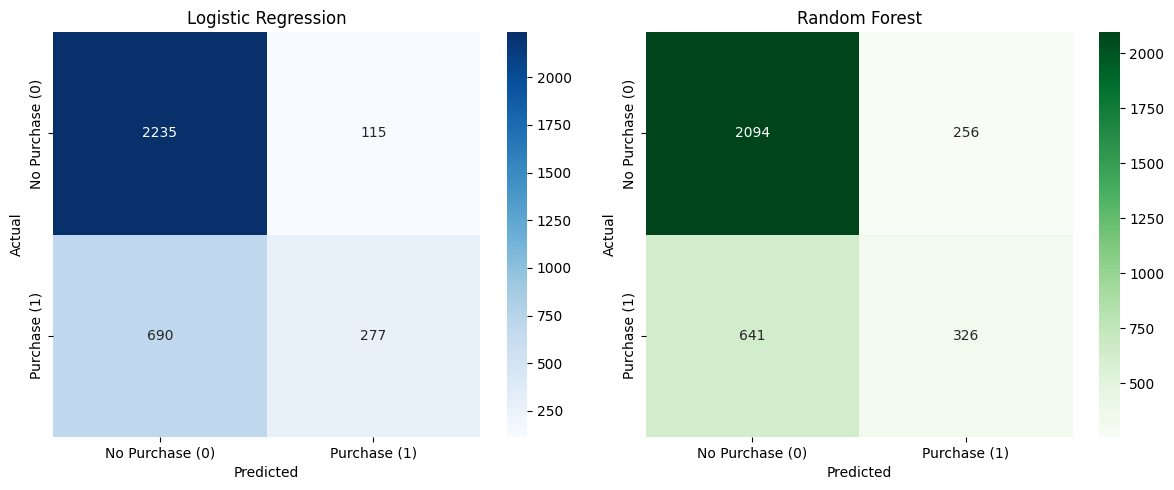

In [ ]:
#Plot confusion matrices
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Plot Logistic Regression confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase (0)", "Purchase (1)"],
    yticklabels=["No Purchase (0)", "Purchase (1)"],
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Plot Random Forest confusion matrix
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Purchase (0)", "Purchase (1)"],
    yticklabels=["No Purchase (0)", "Purchase (1)"],
    ax=axes[1]
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

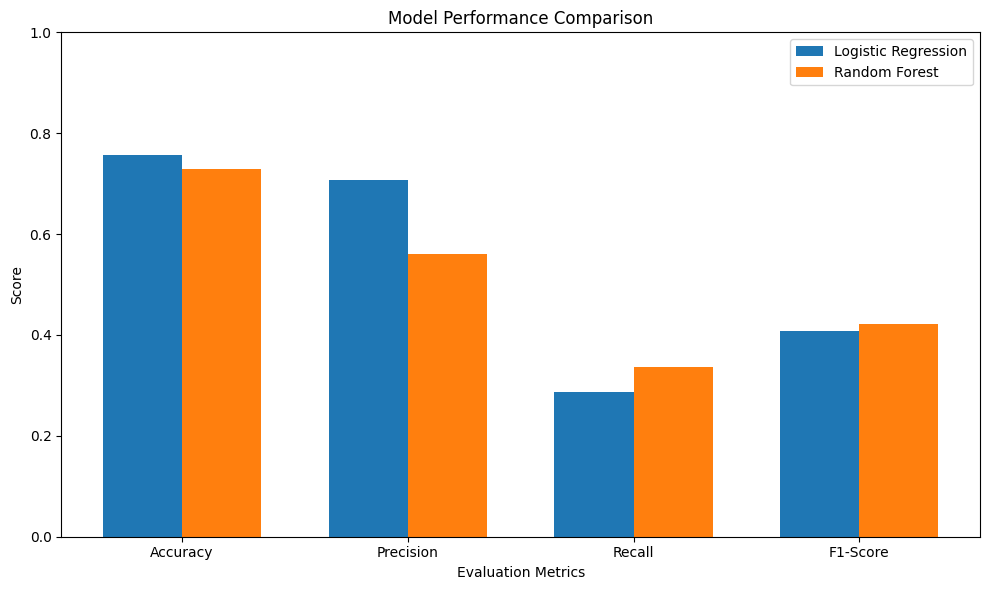

In [ ]:
#Final Model Comparison Graph
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

lr_scores = [
    lr_accuracy,
    lr_precision,
    lr_recall,
    lr_f1
]

rf_scores = [
    rf_accuracy,
    rf_precision,
    rf_recall,
    rf_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width / 2, lr_scores, width, label="Logistic Regression")
plt.bar(x + width / 2, rf_scores, width, label="Random Forest")

plt.title("Model Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
#Model 5

In [ ]:
#Save Dataset, Customer Segments and ML Models

In [ ]:
import os
import joblib

# Create a folder for dashboard files
os.makedirs("dashboard_data", exist_ok=True)

# 1. Save transaction data for sales trends
purchase_df.to_csv(
    "dashboard_data/purchase_data.csv",
    index=False
)

# 2. Save customer segmentation results
rfm_model.to_csv(
    "dashboard_data/customer_segments.csv",
    index=False
)

# 3. Save trained Logistic Regression model
joblib.dump(
    logistic_model,
    "dashboard_data/logistic_model.pkl"
)

# 4. Save trained Random Forest model
joblib.dump(
    random_forest_model,
    "dashboard_data/random_forest_model.pkl"
)

print("All dashboard files saved successfully!")

print("\nSaved files:")
for file in os.listdir("dashboard_data"):
    print(file)

All dashboard files saved successfully!

Saved files:
purchase_data.csv
random_forest_model.pkl
logistic_model.pkl
customer_segments.csv


In [ ]:
import shutil

shutil.make_archive(
    "dashboard_files",
    "zip",
    root_dir="dashboard_data"
)

print("Dashboard ZIP file created successfully!")

Dashboard ZIP file created successfully!


In [ ]:
from google.colab import files

files.download("dashboard_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>